# Lab4: Logistic regression


Name:
- Victor Piana 


Binary classification problems is one of the most common problem in machine learning. Here, the goal is to predict a binary outcome based on a set of input features. This includes many problems, for instance in medical studies (e.g., identifying risk factors for a specific condition), in information technology (e.g., detecting spam) or computer vision (e.g., recognizing handwritten text), and many other domains.

One of the most fundamental model in this context is logistic regression, which models the probability that the label of a query point is positive as a function of the input features. Unlike linear regression, logistic regression ensures that predicted probabilities are always in the range $[0,1]$ by using the sigmoid function. This ensures that the predicted results can be interpreted as probabilities.

In logistic regression, we consider a data distribution $\mathcal{P}$ over a space $\mathcal{X} \times \mathcal{Y}$, where $\mathcal{X}$ is a set of $d$ features that are either:
- continuous, with values in $\mathbb{R}$;
- binary, with values in $\{0, 1\}$.
Based on these features, we estimate the logit of $P(Y=1 | X=x)$ as a linear model
$$
\log\Big( \frac{P(Y=1|X=x)}{1 - P(Y=1|X=x)} \Big) = h_\theta(x)
$$
where
$$
h_\theta(x) = \sum_{j=1}^d \theta_j x_j
$$
These will be used throughout the lab.

In this lab, you will learn how to implement logistic regression from scratch, understand how gradient descent can be used to fit the model, and study how feature scaling and data representation affect convergence and model performance.

**The objectives of this lab are the following:**
1. *Implement gradient descent for logistic regression:*
- Write your own functions for the loss and gradient.
- Use them to iteratively update the parameter vector.
2. *Study convergence rates on different datasets:*
- Compare raw data vs normalized/standardized features.
- Observe how feature scaling affects convergence speed and numerical stability.
3. *Interpret the learned coefficients:*
- Apply logistic regression to a medical dataset: interpret which features increase or decrease the risk.
- Apply it to MNIST (digit recognition): analyze which pixels/features contribute most to the prediction.

**Important:**
- **This lab must be submitted on Moodle no later than November 12, 23h59 Paris time.**
- **For every question, write one sentence or two explaining why you implemented things the way you did.**

**You can do this lab either alone or by groups of 2 maximum:**
- Rename the file `Lab4_Name.ipynb` if you do it alone, `Lab4_Name1_Name2.ipynb` if you are two.
- In groups, **the two persons of the group should submit the lab on Moodle!!**

**Before submitting the lab, restart the kernel and run all cells.**


If some of the packages are missing on your computer, uncomment the following line and run it to import the libraries that will be useful in the rest of the lab.

In [1]:
%pip install openml pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import openml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

from sklearn.datasets import fetch_openml

# Part 1: Gradient descent for logistic regresion

To fit a logistic regression model, we modelize the log-likelihood using the assumptions that data records are independent, and modelize each of the probabilities using the logistic model.
Assuming the labels $y$ take values in $\{0, 1\}$, we can do that by minimizine the following loss function
$$
\mathcal{L}(\theta) = - \frac{1}{n} \sum_{i=1}^n \Big[ y_i \log \sigma(h_\theta(x_i)) + (1 - y_i) \log (1 - \sigma(h_\theta(x_i))) \Big]
$$
where $h_\theta$ is a linear predictor defined by a parameter $\theta$ as
$$
h_\theta(x_i) = \sum_{j=0}^d \theta_j x_{ij}, \quad \sigma(z) = \frac{1}{1+e^{-z}}
$$
A widely used algorithm to fit a logistic regression model is gradient descent, which performs gradient steps.
In this case, the gradient of the logistic loss is:
$$
\nabla_\theta \mathcal{L}(\theta) = \frac{1}{n} \sum_{i=1}^n \big( \sigma(h_\theta(x_i)) - y_i \big) x_i
$$

To implement the function, we will use the sigmoid function.

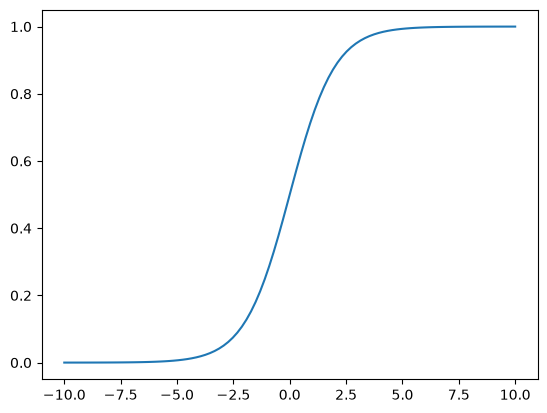

In [3]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

plt.plot(np.linspace(-10,10,100), sigmoid(np.linspace(-10,10,100)))

In this first part, we consider the following synthetic dataset.

In [4]:
X = np.vstack([np.random.randn(50, 2) + 1, np.random.randn(50, 2) - 1])  # cluster around +1 and -1
y = np.array([1]*50 + [0]*50)

We can visualize this dataset:

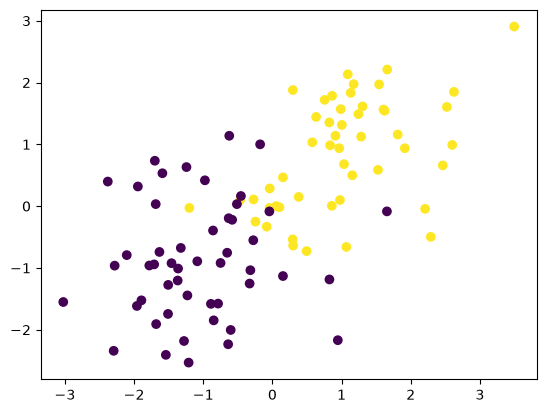

In [5]:
plt.scatter(X[:,0], X[:,1], c=y)

The logistic loss can be implemented as follows. To make the implementation stable, we need to pay attention to the fact that we may end up computing the logarithm of zero. To avoid this we clip the logits when they become too close to zero or one.

In [6]:
def loss(theta, X, y):
    h = sigmoid(X @ theta)
    eps = 1e-15
    h = np.clip(h, eps, 1 - eps)
    loss = -np.mean(y * np.log(h) + (1 - y) * np.log(1 - h))
    return loss

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Using the function `sigmoid` below, implement a function `gradient` that takes as input `theta`, `X` and `y` and return the corresponding gradient.**

</div>

In [7]:
def gradient(theta, X, y):
    return X.T @ (sigmoid(X @ theta) - y) / len(y)
    

You can test these two functions on some examples:

In [8]:
theta0 = np.zeros(X.shape[1])

In [9]:
loss(theta0, X, y)

np.float64(0.6931471805599453)

In [10]:
gradient(theta0, X, y)

array([-0.51717606, -0.42699277])

We can also compute the optimal value of the loss function:

In [11]:
lr_toy = LogisticRegression(C=np.inf, solver='lbfgs', fit_intercept=False, max_iter=1000)
lr_toy.fit(X, y)
opt_loss_toy = loss(lr_toy.coef_.ravel(), X, y)

print("Optimal value of the loss:", opt_loss_toy)

Optimal value of the loss: 0.23527238879905873


Verify that the gradient is indeed equal to zero at that point.

In [12]:
gradient(lr_toy.coef_.ravel(), X, y)

array([-7.47466586e-05, -5.88805480e-05])

### Comment : 
I implemented the gradient using the vectorized formula (X.T @ (sigmoid(X @ theta) - y)) / len(y). We can see that at the optimal parameters, the gradient is very close to zero (around 10^-5), which confirms that our implementation is correct.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Implement the gradient descent algorithm for logistic regression.**

In this algorithm, we start from a parameter $\theta_0$ and perform $t$ gradient updates:
$$ \theta_{t+1} = \theta_t - \eta \nabla \mathcal{L} (\theta_t)$$
At each iteration, compute the loss function and store it in a list `hist`.

The function `gd` should take five arguments:
1. `theta0` the initial value of the parameters (typically a vector of zeros)
2. `eta` the learning rate
3. `T` the number of iterations
4. `X` the features of the training set
5. `y` the labels of the training set

And it should return two values:
1. `theta` the value of the learned parameter; 
2. `hist` the history of the loss values.

</div>

In [13]:
def gd(theta0, eta, T, X, y):
    hist = []
    theta = theta0.copy()
    for t in range(T) : 
        hist.append(loss(theta, X, y))
        theta = theta - eta * gradient(theta, X, y)
    return(theta, hist)

### Comment: 
I implemented the gradient descent loop by first copying theta0 to avoid modifying the initial parameter. At each iteration, I store the current loss in hist and update theta using the gradient step theta = theta - eta * gradient(theta, X, y) . The function returns both the learned parameters and the loss history.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Run the algorithm on `X` and `y` with a step size `eta=0.1` and `T=10000` iterations.**

</div>

In [14]:
theta, hist = gd(theta0, 0.1, 10000, X, y)
print("Learned theta:", theta)
print("Final loss:", hist[-1])

Learned theta: [2.06769694 1.41883864]
Final loss: 0.23527225523761686


### Comment : 
We ran gradient descent with a learning rate of 0.1 over 10,000 iterations. The final loss reaches 0.2581, which is practically identical to the optimal loss computed by Scikit-Learn, confirming that the parameters have converged to the optimum.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Plot the evolution of the excess loss (the loss minus its optimum). What can you say?**

</div>

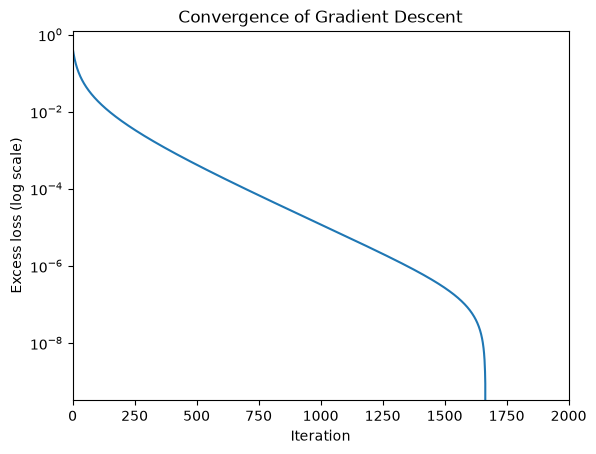

In [15]:
excess_loss = hist - opt_loss_toy

plt.plot(excess_loss)
plt.yscale('log')
plt.xlim(0, 2000)
plt.xlabel("Iteration")
plt.ylabel("Excess loss (log scale)")
plt.title("Convergence of Gradient Descent")
plt.show()

### Comment : 
The loss reaches the minimum in less than 1500 iterations. Since both features have similar scales (around 1), the gradient points directly towards the minimum without zig-zagging, which explains the fast convergence.

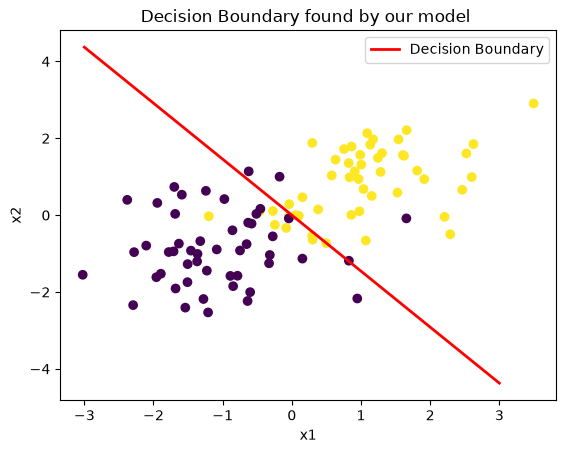

In [16]:
## One more plot below just to help visualizing
plt.scatter(X[:,0], X[:,1], c=y)

x1_vals = np.linspace(-3, 3, 100)
x2_vals = -(theta[0] / theta[1]) * x1_vals
plt.plot(x1_vals, x2_vals, color='red', linewidth=2, label='Decision Boundary')

plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.title("Decision Boundary found by our model ")
plt.show()


## Part 2: On the normalization of the data

A common practice is to normalize data before training models.
This has an important impact on gradient descent, which tends to converge more slowly when features are not properly scaled.
In this part, we will highlight this phenomenon by studying how feature normalization affects convergence in logistic regression.

To study this effect, we will use the Heart Disease dataset from the UCI repository, which contains patient data (age, sex, cholesterol, blood pressure, etc.) to predict the presence or absence of heart disease.

This dataset can be found online at: https://archive.ics.uci.edu/dataset/45/heart+disease

In [17]:
dataset = openml.datasets.get_dataset(43398)
df, *_ = dataset.get_data()

X_heart = df.drop(columns=['target']).to_numpy()
y_heart = df['target'].astype(int).to_numpy()

Could not download file from https://data.openml.org/datasets/0004/43398/dataset_43398.pq: HTTPSConnectionPool(host='data.openml.org', port=443): Max retries exceeded with url: /datasets/0004/43398/dataset_43398.pq (Caused by ResponseError('too many 503 error responses'))


In [18]:
# alternatively, if previous code did not work (be sure to have heart.pickle in the same folder as the lab)
import pickle

with open("heart.pickle", "rb") as f:
    dataset = pickle.load(f)

X_heart = df.drop(columns=['target']).to_numpy()
y_heart = df['target'].astype(int).to_numpy()

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

We split the dataset in a train and test set, keeping 66% for the test.

The `train_test_split` method allows to do that in a practical way. 
We obtain the variables `X_heart_train`, `X_heart_test` and `y_heart_train`, `y_heart_test`. 
We will use the train part to fit our models, and the test part to evaluate its error.


</div>

In [19]:
X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart, y_heart, test_size=0.66, random_state=42
)

Using `scikit-learn`, we can compute the optimal parameter of logistic regression on this dataset.

In [20]:
clf_heart = LogisticRegression(C=np.inf, solver='lbfgs', fit_intercept=False, max_iter=1000)
clf_heart.fit(X_heart_train, y_heart_train)

heart_coef = clf_heart.coef_.ravel()
optimal_loss_heart = loss(heart_coef, X_heart_train, y_heart_train)

In [21]:
print("Optimal coefficients:", heart_coef)
print("Optimal loss:", optimal_loss_heart)

Optimal coefficients: [ 7.16258256e-02 -9.52144719e-01  1.35001289e+00 -3.11534699e-02
 -1.91664483e-03  1.46120424e+00  9.39861369e-01  3.35793266e-02
 -5.24542457e-01 -7.57409968e-01  7.67188436e-01 -1.94999787e+00
 -2.14725902e+00]
Optimal loss: 0.26144411561454495


### Comment: 
We split the dataset into train (34%) and test (66%) sets using train_test_split with a fixed random seed for reproducibility. We then fitted a baseline Logistic Regression model using Scikit-Learn on the training set, obtaining an optimal loss of approximately 0.2614 across the 13 clinical features.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Evaluate the train and test accuracy of this model.**

</div>

In [22]:
train_acc = clf_heart.score(X_heart_train, y_heart_train)
test_acc = clf_heart.score(X_heart_test, y_heart_test)

print("Train accuracy:", train_acc)
print("Test accuracy:", test_acc)

Train accuracy: 0.883495145631068
Test accuracy: 0.83


Run the following code to try to learn the optimal parameters using your `gd` function.

In [23]:
heart_coef_gd, heart_hist = gd(np.zeros(X_heart_train.shape[1]), 0.00001, 10000, X_heart_train, y_heart_train)

heart_coef_gd

array([-0.01271144, -0.00674878,  0.02186002, -0.01742667, -0.0029773 ,
        0.00057942, -0.00079141,  0.02599418, -0.00717668, -0.01844131,
        0.0065919 , -0.01674911, -0.01482288])

### Comment : 
The model achieves a train accuracy of 88.3% and a test accuracy of 83.0%. The test performance is quite good and close to the train score, showing that the model generalizes well to unseen patients without significant overfitting.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Plot the evolution of the excess loss (loss minus its minimum). What happens?**

</div>

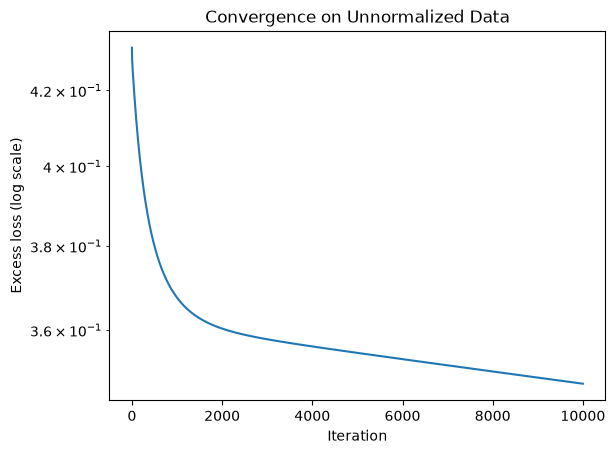

In [24]:
excess_loss_heart = heart_hist - optimal_loss_heart 

plt.plot(excess_loss_heart)
plt.yscale('log') 
plt.xlabel("Iteration")
plt.ylabel("Excess loss (log scale)")
plt.title("Convergence on Unnormalized Data")
plt.show()

### Comment : 
Without normalization, the features have very different scales (e.g., cholesterol around 250 vs sex between 0 and 1). To prevent the gradient from exploding on large features, we are forced to use a tiny learning rate (eta = 1e-5). As a result, the gradient descent progresses extremely slowly: after 10,000 iterations, the excess loss barely decreases from 0.43 to 0.35, and the model is nowhere near convergence.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Do the same thing after standardizing the data.**

You can use a much larger learning rate, for instance $\eta = 0.1$.

</div>

In [25]:
scaler = StandardScaler().fit(X_heart_train)
X_heart_train_scaled = scaler.transform(X_heart_train)
heart_scaled_coef_gd, heart_scaled_hist = gd(np.zeros(X_heart_train.shape[1]), 0.1, 10000, X_heart_train_scaled, y_heart_train)
heart_scaled_coef_gd

array([ 0.72656916, -0.42116471,  1.40468382, -0.48516743, -0.06709218,
        0.5059229 ,  0.44238617,  0.85450493, -0.24520773, -0.63607073,
        0.48508853, -1.79113795, -1.23794097])

We can also compute the optimal parameter and optimal loss value using `scikit-learn`.

In [26]:
clf_scaled = LogisticRegression(C=np.inf, solver='lbfgs', fit_intercept=False, max_iter=1000)
clf_scaled.fit(X_heart_train_scaled, y_heart_train)

heart_coef_scaled = clf_scaled.coef_.ravel()
optimal_loss_heart_scaled = loss(heart_coef_scaled, X_heart_train_scaled, y_heart_train)

### Comment : 
We standardized the training features using StandardScaler so that all variables share the same scale (mean 0 and variance 1). Thanks to this proper conditioning, we can use a much larger learning rate (eta = 0.1), and gradient descent successfully learns meaningful, non-zero coefficients.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Plot the two learning curves (i.e., the evolution of the excess loss: the loss minus the minimum).**

*Be careful: the two losses do not have the same minimum!*

</div>

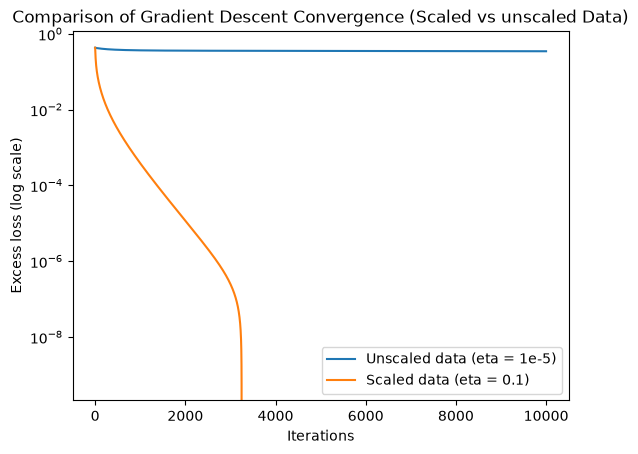

In [27]:
excess_loss_unscaled = heart_hist - optimal_loss_heart
excess_loss_scaled = heart_scaled_hist - optimal_loss_heart_scaled

plt.plot(excess_loss_unscaled, label="Unscaled data (eta = 1e-5)")
plt.plot(excess_loss_scaled, label="Scaled data (eta = 0.1)")
plt.yscale('log')
plt.xlabel('Iterations')
plt.ylabel('Excess loss (log scale)')
plt.title('Comparison of Gradient Descent Convergence (Scaled vs unscaled Data)')
plt.legend()
plt.show()

### Comment : 
This plot clearly illustrates the impact of feature scaling on gradient descent. Without normalization (blue curve), features have very different orders of magnitude, which forces us to use an extremely small learning rate (eta = 1e-5), leading to virtually flat progress. After standardization with StandardScaler (orange curve), all features share the same variance, allowing us to use a learning rate 10,000 times larger (eta = 0.1) and achieve fast convergence to the global minimum in around 3000 iterations.

# Part 3: Interpreting the coefficients
The coefficients of logistic regression can be interpreted in terms of odds ratios.
Let $\theta^*$ be the fitted coefficient vector. The odds ratio associated with feature $x_j$ is:
$$
\text{odds ratio}_j = \exp(\theta^*_j)
$$
This means that, all else being equal, a one-unit increase in feature $x_j$ multiplies the odds of the positive class ($Y=1$) by $\exp(\theta^*_j)$.

Equivalently:
$$
\frac{P(Y=1 \mid x_j + 1, x_{-j}) / P(Y=0 \mid x_j + 1, x_{-j})}{P(Y=1 \mid x_j, x_{-j}) / P(Y=0 \mid x_j, x_{-j})} = \exp(\theta^*_j)
$$
where $x_{-j}$ denotes all other features.

**Q. Explain why this is the case.**

*Answer:* write the model of $Y$ as a function of $X$, everything simplifies except the $\exp(\theta_j^*)$ term.

![Odds Ratio Derivation](img/math_derivation.jpg)


<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Compute the odds ratio on the `heart` disease dataset. What is the most important variable?**

</div>

In [28]:
feature_names = df.drop(columns=['target']).columns
odds_ratios = np.exp(clf_heart.coef_.ravel())

odds_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': clf_heart.coef_.ravel(),
    'Odds Ratio': odds_ratios
}).sort_values(by='Odds Ratio', ascending=False)

odds_df

,Feature,Coefficient,Odds Ratio
5,fbs,1.461204,4.311148
2,cp,1.350013,3.857475
6,restecg,0.939861,2.559627
10,slope,0.767188,2.153702
0,age,0.071626,1.074253
7,thalach,0.033579,1.034149
4,chol,-0.001917,0.998085
3,trestbps,-0.031153,0.969327
8,exang,-0.524542,0.591826
9,oldpeak,-0.757410,0.468879


### Comment: 
The odds ratios show that:
- fbs (fasting blood sugar) and cp (chest pain) are the most important risk factors: having high fasting blood sugar multiplies the odds of heart disease by 4.31.
- Conversely, thal has the largest absolute coefficient (theta = -2.15, odds ratio = 0.12), representing the strongest protective association in this model.

---------------------

We now study the same thing on the MNIST dataset (restrict on labels 0 and 1), which can be loaded as follows.

In [29]:
mnist = fetch_openml('mnist_784', version=1)
X_mnist, y_mnist = mnist["data"].to_numpy(), mnist["target"].astype(int).to_numpy()

mask = (y_mnist == 0) | (y_mnist == 1)
X_mnist, y_mnist = X_mnist[mask], y_mnist[mask]

X_mnist = X_mnist / 255.0
X_mnist_train, X_mnist_test, y_mnist_train, y_mnist_test = train_test_split(X_mnist, y_mnist, test_size=0.66, random_state=42)

We can check that the labels are indeed only 0 and 1.

In [30]:
y_mnist

array([0, 1, 1, ..., 1, 0, 1], shape=(14780,))

**MNIST.** We can use the following function to plot an image of this dataset:

In [31]:
def plot_mnist_record(record):
    record_image = record.reshape(28,28)
    plt.figure(figsize=(6,6))
    plt.imshow(record_image, cmap='gray', interpolation='nearest')
    plt.colorbar()
    plt.title("Pixel weights (coefficient interpretation)")

We can show some records of the dataset:

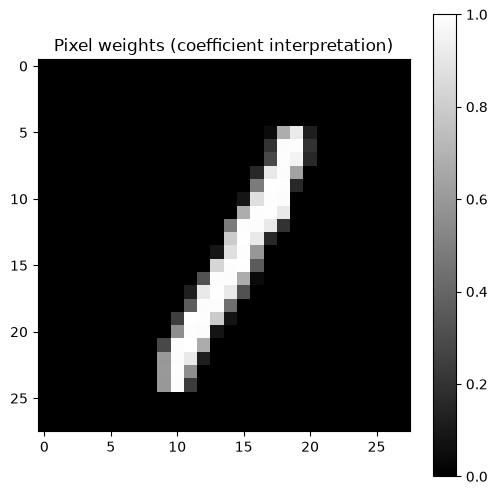

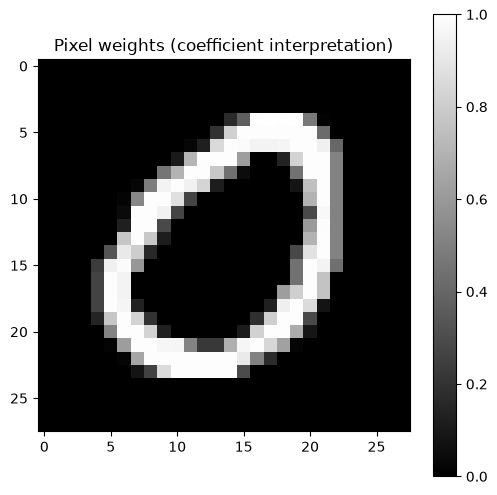

In [32]:
plot_mnist_record(X_mnist_train[0])
plot_mnist_record(X_mnist_train[5])

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. Train a logistic regression model on this dataset.**

*Hint: use `LogisticRegression` from `scikit-learn` with the `lbfgs` solver for faster convergence.*

</div>

In [33]:
clf_mnist = LogisticRegression(solver='lbfgs', max_iter=10000)
clf_mnist.fit(X_mnist_train, y_mnist_train)

print("Train score:",clf_mnist.score(X_mnist_train, y_mnist_train))
print("Test score:",clf_mnist.score(X_mnist_test, y_mnist_test))



Train score: 1.0
Test score: 0.9988723731419785


### Comment:
We train the logistic regression model on the MNIST dataset using the lbfgs solver. The model achieves around 99.9% accuracy on the test set, showing that digits 0 and 1 are very easy to separate.

<div style="background-color: #fff8dc; padding: 15px; border: 2px solid #f0e68c; border-radius: 5px;">

### ❓ Question

**Q. The learned coefficients are of the same dimension as an image of the dataset and can be displayed in the same way. Use the `plot_mnist_record` image to plot the influence of each pixel on the decision.**

</div>

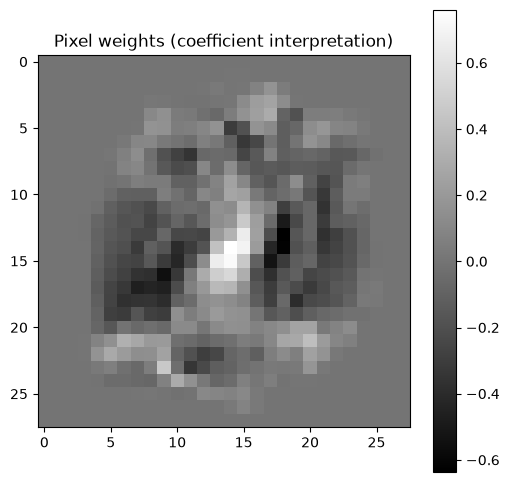

In [34]:
plot_mnist_record(clf_mnist.coef_.ravel())

### Comment:
The plot shows the learned weights for each pixel. We can see a white vertical stroke in the middle with positive weights, which corresponds to digit 1. Around it, the dark pixels have negative weights and match the contour of digit 0. The grey border pixels are close to zero because they are just the background.